# Model 3: Czy gatunki muzyczne mają charakterystyczne cechy audio?
### Klasteryzacja i klasyfikacja wieloklasowa – część praktyczna

Odpowiadamy na pytanie w dwóch krokach:

| | Krok 1: **klasteryzacja** | Krok 2: **klasyfikacja** |
|---|---|---|
| Co dostaje model | tylko cechy audio, **bez** gatunków | cechy audio **i** gatunki |
| Pytanie | czy utwory same układają się w grupy podobne do gatunków? | jak dobrze model nauczy się rozpoznawać gatunek? |

Jeśli grupy znalezione bez podpowiedzi pokrywają się z gatunkami, to gatunki mają swój „odcisk palca” w dźwięku.

| | Część A – omówienie | | Część B – zadania |
|---|---|---|---|
| 1 | Dane i „odcisk palca” gatunków | Z1 | Inna liczba klastrów |
| | **Krok 1 – klasteryzacja** | Z2 | k-NN na mniejszej liczbie cech |
| 2 | K-means | | |
| 3 | Porównanie klastrów z gatunkami | | |
| 4 | Wizualizacja (PCA) | | |
| | **Krok 2 – klasyfikacja** | | |
| 5 | Podział, baseline, regresja logistyczna | | |
| 6 | Pięć klasyfikatorów w jednej pętli | | |
| 7 | Macierz pomyłek 10×10 | | |
| 8 | Wnioski | | |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn import (model_selection, linear_model, tree, neighbors, svm, ensemble,
                     metrics, preprocessing, pipeline, dummy, cluster, decomposition)

RANDOM_STATE = 42   # ta sama liczba = te same wyniki przy każdym uruchomieniu
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

## 1. Dane i „odcisk palca” gatunków

In [2]:
# Szukamy pliku lokalnie; jeśli go nie ma (np. Google Colab) – pobieramy z GitHuba
URL = "https://raw.githubusercontent.com/mzntk/ml-seminarium-projekt/main/dane/viral_songs.csv"
kandydaci = [Path("../dane/viral_songs.csv"), Path("dane/viral_songs.csv"), Path("../../dane/viral_songs.csv")]
sciezka = next((p for p in kandydaci if p.exists()), URL)

df = pd.read_csv(sciezka)
print("Wczytano z:", sciezka)
print("Rozmiar tabeli:", df.shape)

CECHY_AUDIO = ["duration_sec", "danceability", "energy", "valence", "tempo_bpm",
               "acousticness", "instrumentalness", "speechiness", "liveness", "loudness_db"]
GATUNKI = sorted(df["genre"].unique())

print("\nLiczba utworów w każdym gatunku:")
print(df["genre"].value_counts())

Wczytano z: ../dane/viral_songs.csv
Rozmiar tabeli: (10000, 17)

Liczba utworów w każdym gatunku:
genre
Rock          1084
Hip-Hop       1052
Latin         1030
Pop           1002
Indie          993
Electronic     991
Classical      991
Jazz           965
R&B            950
Country        942
Name: count, dtype: int64


10 gatunków po ok. 1000 utworów: klasy są zrównoważone, więc zgadywanie dawałoby ok. 10% trafności.

Mapa poniżej pokazuje średnie cech w każdym gatunku, przeliczone tak, żeby dało się je porównać: 0 to średnia całego zbioru, czerwone pola to więcej niż przeciętnie, niebieskie mniej.

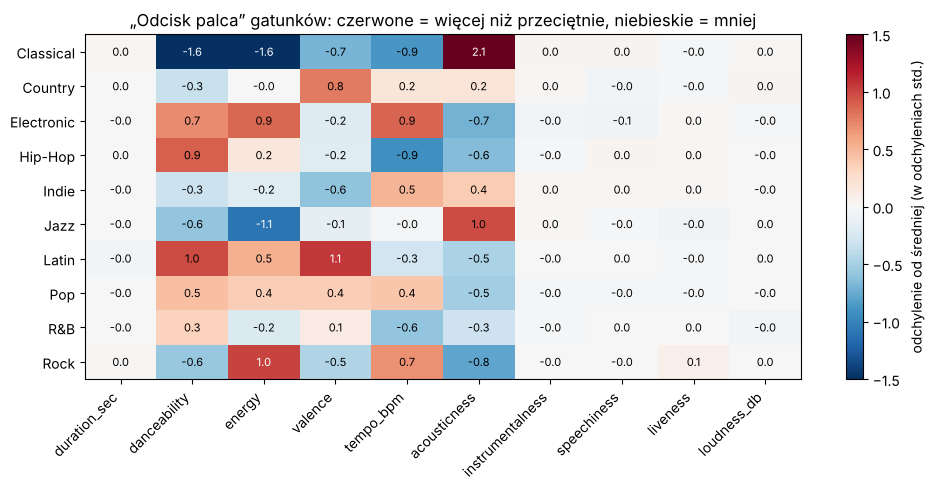

In [3]:
srednie = df.groupby("genre")[CECHY_AUDIO].mean()
srednie_std = (srednie - df[CECHY_AUDIO].mean()) / df[CECHY_AUDIO].std()

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(srednie_std.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(CECHY_AUDIO)), CECHY_AUDIO, rotation=45, ha="right")
ax.set_yticks(range(len(GATUNKI)), srednie_std.index)
for i in range(len(GATUNKI)):
    for j in range(len(CECHY_AUDIO)):
        v = srednie_std.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 1 else "black")
fig.colorbar(im, label="odchylenie od średniej (w odchyleniach std.)")
ax.set_title("„Odcisk palca” gatunków: czerwone = więcej niż przeciętnie, niebieskie = mniej")
plt.tight_layout()
plt.show()

Widać „odciski palców”: Classical jest bardzo akustyczny, mało energetyczny i mało taneczny; Rock i Electronic są energetyczne i szybkie; Latin i Country pogodne (`valence`); Hip-Hop i R&B taneczne, ale wolniejsze.

**Połowa kolumn jest prawie biała:** `duration_sec`, `instrumentalness`, `speechiness`, `liveness`, `loudness_db` są dla wszystkich gatunków takie same (zbiór jest syntetyczny). Gatunki różni tylko **5 cech**. Zapisujemy je:

In [4]:
CECHY_DOBRE = ["danceability", "energy", "valence", "acousticness", "tempo_bpm"]

---
# KROK 1: Klasteryzacja – czy utwory same układają się w gatunki?

## 2. K-means

Trzy decyzje przed startem:
- **Skalowanie:** K-means liczy odległości, więc bez skalowania `tempo_bpm` (wartości ok. 100) zagłuszyłoby cechy 0–1.
- **Cechy:** bierzemy 5 cech, które różnią gatunki.
- **Liczba klastrów:** k = 4, bo tyle grup łatwo opisać (inne k sprawdzimy w zadaniu Z1).

**Kolumny `genre` NIE dajemy modelowi.**

In [5]:
skaler_k = preprocessing.StandardScaler()
X_klast = skaler_k.fit_transform(df[CECHY_DOBRE])     # tylko cechy, bez gatunku!

kmeans = cluster.KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_klast)
klastry = kmeans.predict(X_klast)

print("Numery klastrów pierwszych 15 utworów:", klastry[:15])
print("Ile utworów w każdym klastrze:", np.bincount(klastry))

Numery klastrów pierwszych 15 utworów: [1 3 2 0 1 1 0 3 3 2 3 2 2 0 0]
Ile utworów w każdym klastrze: [2112 2573 2360 2955]


Model zwrócił dla każdego utworu **numer grupy** (0–3). Numery są przypadkowe, więc najpierw sprawdzamy, czym klastry się różnią.

## 3. Porównanie klastrów z gatunkami

Środki klastrów w oryginalnych jednostkach. Na ich podstawie kod nadaje klastrom nazwy:

In [6]:
centra = pd.DataFrame(skaler_k.inverse_transform(kmeans.cluster_centers_), columns=CECHY_DOBRE)

# Nadajemy klastrom nazwy na podstawie ich środków (numery klastrów są przypadkowe)
nazwy = {}
akust = centra["acousticness"].idxmax()
nazwy[akust] = "A: spokojne, akustyczne"
reszta = centra.drop(index=akust)
nazwy[reszta["tempo_bpm"].idxmax()] = "B: szybkie, energetyczne"
nazwy[reszta["tempo_bpm"].idxmin()] = "C: wolne, taneczne"
nazwy[[k for k in centra.index if k not in nazwy][0]] = "D: pogodne (wysoka valence)"

centra.index = [nazwy[k] for k in centra.index]
centra.sort_index().round(2)

,danceability,energy,valence,acousticness,tempo_bpm
"A: spokojne, akustyczne",0.39,0.41,0.50,0.69,102.84
"B: szybkie, energetyczne",0.59,0.77,0.49,0.18,127.96
"C: wolne, taneczne",0.75,0.67,0.55,0.17,93.71
D: pogodne (wysoka valence),0.69,0.70,0.79,0.23,114.00


Teraz kluczowy moment: zestawiamy klastry z **prawdziwymi gatunkami**, których model nie widział. `pd.crosstab` liczy, ile utworów z danego gatunku trafiło do danego klastra.

klaster,"A: spokojne, akustyczne","B: szybkie, energetyczne","C: wolne, taneczne",D: pogodne (wysoka valence)
genre,,,,
Classical,991,0,0,0
Country,90,179,103,570
Electronic,0,665,123,203
Hip-Hop,0,63,865,124
Indie,228,552,110,103
Jazz,784,48,56,77
Latin,0,46,281,703
Pop,3,341,186,472
R&B,16,109,582,243


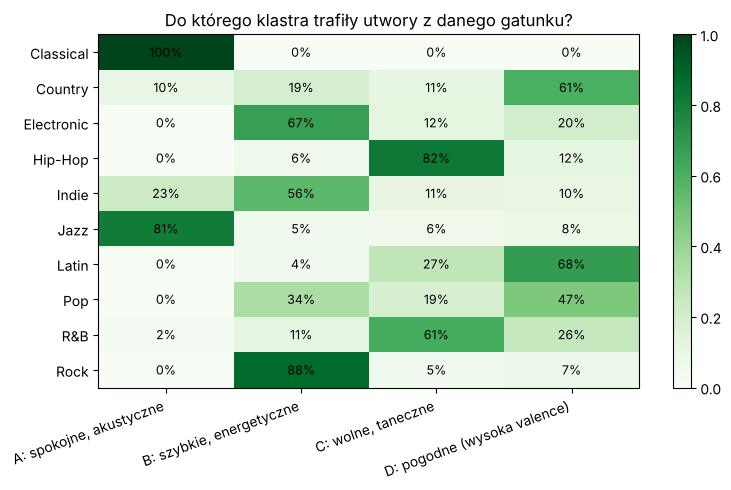

In [7]:
df["klaster"] = pd.Series(klastry).map(nazwy)

tabela_krzyzowa = pd.crosstab(df["genre"], df["klaster"])
display(tabela_krzyzowa)

# To samo w procentach: jaka część każdego gatunku trafiła do którego klastra
procenty = pd.crosstab(df["genre"], df["klaster"], normalize="index")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(procenty.values, cmap="Greens", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(procenty.shape[1]), procenty.columns, rotation=20, ha="right")
ax.set_yticks(range(procenty.shape[0]), procenty.index)
for i in range(procenty.shape[0]):
    for j in range(procenty.shape[1]):
        ax.text(j, i, f"{procenty.values[i, j]:.0%}", ha="center", va="center", fontsize=9)
ax.set_title("Do którego klastra trafiły utwory z danego gatunku?")
fig.colorbar(im)
plt.tight_layout()
plt.show()

**Co widać?** K-means, nie wiedząc nic o gatunkach, znalazł **„rodziny” gatunków**:

- **A: spokojne, akustyczne** – cała muzyka klasyczna i większość jazzu,
- **B: szybkie, energetyczne** – Rock, Electronic, spora część Indie,
- **C: wolne, taneczne** – Hip-Hop i R&B,
- **D: pogodne** – Latin, Country, duża część Popu.

Classical wyodrębnia się w 100%. **Pop jest rozmyty** po kilku klastrach: to raczej styl i popularność niż konkretne brzmienie.

**A gdyby k = 10, tyle ile gatunków?** Zgodność klastrów z gatunkami mierzymy liczbą **ARI**: 0 to zgodność jak przy losowym podziale, 1 to podział identyczny z gatunkami.

In [8]:
kmeans10 = cluster.KMeans(n_clusters=10, n_init=10, random_state=RANDOM_STATE).fit(X_klast)

print("ARI dla k = 4: ", round(metrics.adjusted_rand_score(df["genre"], klastry), 3))
print("ARI dla k = 10:", round(metrics.adjusted_rand_score(df["genre"], kmeans10.labels_), 3))

ARI dla k = 4:  0.221
ARI dla k = 10: 0.325


Nawet przy 10 klastrach ARI wynosi ok. 0.3, czyli daleko od 1. Dźwięk wyznacza przede wszystkim **rodziny** gatunków, a pojedyncze gatunki mocno się przenikają.

## 4. Wizualizacja (PCA)

PCA rzutuje 5 cech na płaszczyznę, żeby dało się je narysować. Po lewej kolory to klastry K-means, po prawej prawdziwe gatunki.

Jaką część zmienności danych pokazuje wykres 2D: 0.66


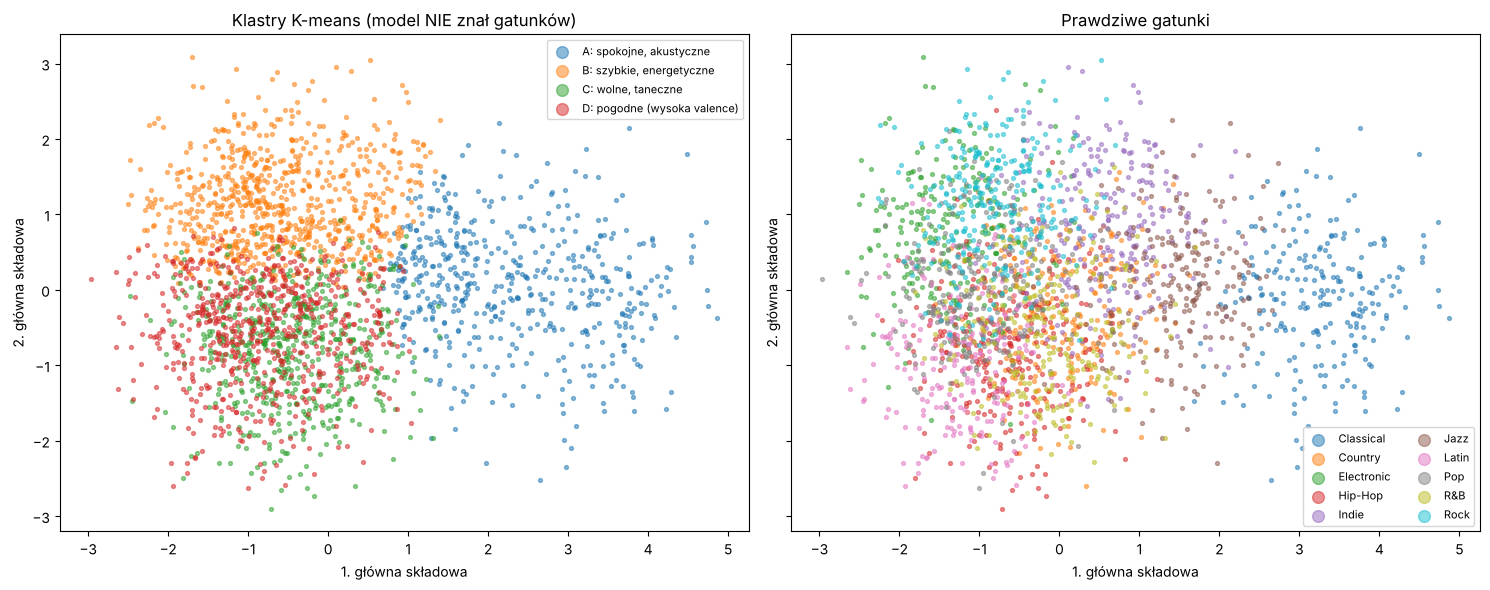

In [9]:
pca = decomposition.PCA(n_components=2)
X_2d = pca.fit_transform(X_klast)
print("Jaką część zmienności danych pokazuje wykres 2D:", round(pca.explained_variance_ratio_.sum(), 3))

proba = np.random.default_rng(RANDOM_STATE).choice(len(df), 2500, replace=False)  # 2500 punktów, żeby było czytelnie
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

for nazwa_k in sorted(df["klaster"].unique()):
    m = (df["klaster"].values[proba] == nazwa_k)
    axes[0].scatter(X_2d[proba][m, 0], X_2d[proba][m, 1], s=8, alpha=0.5, label=nazwa_k)
axes[0].set_title("Klastry K-means (model NIE znał gatunków)")
axes[0].legend(markerscale=3, fontsize=8)

kolory = plt.cm.tab10(np.linspace(0, 1, 10))
for g, kol in zip(GATUNKI, kolory):
    m = (df["genre"].values[proba] == g)
    axes[1].scatter(X_2d[proba][m, 0], X_2d[proba][m, 1], s=8, alpha=0.5, color=kol, label=g)
axes[1].set_title("Prawdziwe gatunki")
axes[1].legend(markerscale=3, fontsize=8, ncol=2)

for ax in axes:
    ax.set_xlabel("1. główna składowa")
    ax.set_ylabel("2. główna składowa")
plt.tight_layout()
plt.show()

Po prawej widać, że gatunki **zachodzą na siebie**. Osobną „wyspę” tworzy tylko Classical (i częściowo Jazz). K-means (po lewej) tnie tę chmurę na kawałki, które z grubsza odpowiadają rodzinom gatunków.

### Wniosek z kroku 1

**Czy utwory same układają się w gatunki? Częściowo.** Bez podpowiedzi algorytm odkrywa rodziny gatunków, a muzyka klasyczna wyodrębnia się idealnie. Ale 10 osobnych gatunków nie „wychodzi samo”. Sprawdźmy, ile da model, któremu **powiemy**, jaki jest gatunek.

---
# KROK 2: Klasyfikacja – uczymy model rozpoznawać gatunek

## 5. Podział, baseline i regresja logistyczna

Tym razem bierzemy wszystkie 10 cech audio (sprawdzimy, czy modele poradzą sobie z bezużytecznymi cechami), a gatunek jest zmienną celu **y**. Pomijamy `viral` i `streams`: pytamy o dźwięk, nie o popularność.

In [10]:
X = df[CECHY_AUDIO]
y = df["genre"]

X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, train_size=0.7, stratify=y, random_state=RANDOM_STATE)

baseline = dummy.DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Zbiór treningowy:", X_train.shape, "| testowy:", X_test.shape)
print("Accuracy baseline (zawsze najczęstszy gatunek):",
      round(metrics.accuracy_score(y_test, baseline.predict(X_test)), 3))

Zbiór treningowy: (7000, 10) | testowy: (3000, 10)
Accuracy baseline (zawsze najczęstszy gatunek): 0.108


Baseline ma ok. **10%**, czyli tyle, ile zgadywanie.

Regresja logistyczna sama obsługuje 10 klas: dla każdego utworu liczy 10 prawdopodobieństw i wybiera największe.

In [11]:
model_lr = pipeline.make_pipeline(preprocessing.StandardScaler(),
                                  linear_model.LogisticRegression(max_iter=1000))
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

print(metrics.classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

   Classical       0.93      0.94      0.93       297
     Country       0.55      0.52      0.54       283
  Electronic       0.60      0.58      0.59       297
     Hip-Hop       0.58      0.62      0.60       316
       Indie       0.56      0.56      0.56       298
        Jazz       0.69      0.71      0.70       289
       Latin       0.55      0.58      0.57       309
         Pop       0.37      0.32      0.34       301
         R&B       0.43      0.42      0.43       285
        Rock       0.74      0.79      0.76       325

    accuracy                           0.61      3000
   macro avg       0.60      0.60      0.60      3000
weighted avg       0.60      0.61      0.60      3000



Każdy wiersz raportu to jeden gatunek. **macro avg** to średnia z 10 gatunków. Od razu widać różnice: **Classical** rozpoznawany niemal bezbłędnie (recall 0.94), **Rock** bardzo dobrze (0.79), a **Pop** najgorzej (0.32).

## 6. Pięć klasyfikatorów w jednej pętli

Ten sam schemat co w notebooku 02. Przy wielu klasach zamiast F1 jednej klasy liczymy **macro F1**.

In [12]:
modele = {
    "LogisticRegression": pipeline.make_pipeline(preprocessing.StandardScaler(),
                                                 linear_model.LogisticRegression(max_iter=1000)),
    "DecisionTree":       tree.DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNeighbors":         pipeline.make_pipeline(preprocessing.StandardScaler(),
                                                 neighbors.KNeighborsClassifier()),
    "SVC":                pipeline.make_pipeline(preprocessing.StandardScaler(),
                                                 svm.SVC(random_state=RANDOM_STATE)),
    "RandomForest":       ensemble.RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

wyniki = []
for nazwa, model in modele.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    wyniki.append({
        "model": nazwa,
        "accuracy (trening)": metrics.accuracy_score(y_train, model.predict(X_train)),
        "accuracy (test)":    metrics.accuracy_score(y_test, y_pred),
        "macro F1":           metrics.f1_score(y_test, y_pred, average="macro"),
    })

tabela = pd.DataFrame(wyniki).set_index("model").round(3)
tabela

,accuracy (trening),accuracy (test),macro F1
model,,,
LogisticRegression,0.620,0.606,0.601
DecisionTree,1.000,0.476,0.475
KNeighbors,0.672,0.495,0.488
SVC,0.666,0.590,0.585
RandomForest,1.000,0.592,0.586


**Co widać?**

- Najlepsze modele trafiają gatunek w ok. **60%** przypadków, czyli **6 razy lepiej niż zgadywanie**.
- Najlepsza znów jest **regresja logistyczna** (≈ 0.61); SVC i las losowy są tuż za nią (≈ 0.59).
- Drzewo decyzyjne znów ma 100% na treningu i najsłabszy wynik na teście: przeuczenie.
- k-NN cierpi przez 5 bezużytecznych cech, które psują mu odległości (zadanie Z2).

## 7. Macierz pomyłek 10×10

Dla najlepszego modelu sprawdzamy, **z czym** myli gatunki. Każdy wiersz sumuje się do 100%: komórka mówi, jaki odsetek utworów danego gatunku model nazwał gatunkiem z kolumny. Na przekątnej są trafienia.

Najlepszy model: LogisticRegression


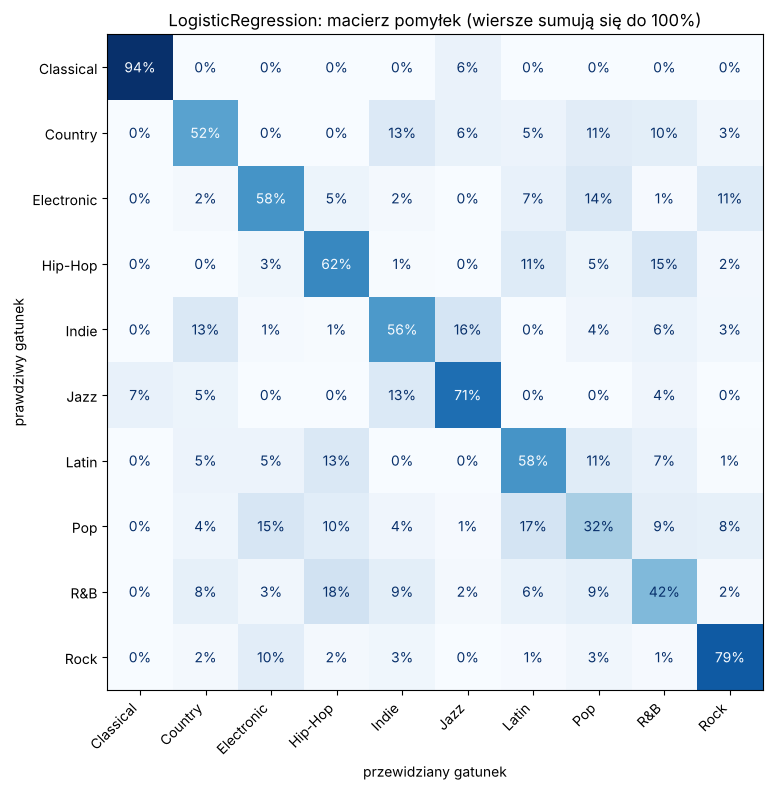

In [13]:
najlepszy = tabela["accuracy (test)"].idxmax()
y_pred_best = modele[najlepszy].predict(X_test)
print("Najlepszy model:", najlepszy)

fig, ax = plt.subplots(figsize=(9, 8))
metrics.ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, labels=GATUNKI, normalize="true", values_format=".0%",
    cmap="Blues", ax=ax, colorbar=False)
ax.set_xlabel("przewidziany gatunek")
ax.set_ylabel("prawdziwy gatunek")
ax.set_title(f"{najlepszy}: macierz pomyłek (wiersze sumują się do 100%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Najczęstsze pomyłki w liczbach:

In [14]:
cm = metrics.confusion_matrix(y_test, y_pred_best, labels=GATUNKI)
pomylki = pd.DataFrame(cm, index=GATUNKI, columns=GATUNKI).stack()
pomylki.index.names = ["prawdziwy", "przewidziany"]
pomylki = pomylki[pomylki.index.get_level_values(0) != pomylki.index.get_level_values(1)]
pomylki.sort_values(ascending=False).head(8).rename("liczba pomyłek").to_frame()

,,liczba pomyłek
prawdziwy,przewidziany,
R&B,Hip-Hop,51
Pop,Latin,50
Indie,Jazz,48
Hip-Hop,R&B,46
Pop,Electronic,45
Latin,Hip-Hop,41
Electronic,Pop,41
Indie,Country,40


Pomyłki **pokrywają się z rodzinami gatunków z kroku 1**: model myli gatunki, które K-means wrzucał do wspólnego klastra (R&B z Hip-Hopem, Pop z Latin i Electronic, Indie z Jazzem i Country). Klasteryzacja i klasyfikacja mówią więc to samo, tylko klasyfikator dzięki etykietom lepiej rozróżnia gatunki wewnątrz rodziny.

## 8. Wnioski – czy gatunki mają charakterystyczne cechy audio?

**Tak, ale nie wszystkie w równym stopniu.**

| | Krok 1: klasteryzacja (bez etykiet) | Krok 2: klasyfikacja (z etykietami) |
|---|---|---|
| Co się udało | odkryć 4 „rodziny” gatunków; Classical wyodrębniony w 100% | rozpoznać gatunek w ok. 60% przypadków (zgadywanie: 10%) |
| Czego się nie udało | odtworzyć 10 osobnych gatunków (ARI ≈ 0.3) | odróżnić gatunki z tej samej rodziny (Pop, R&B, Indie) |

- **Najbardziej charakterystyczne:** Classical (akustyczny, spokojny), Rock (energetyczny, szybki), Jazz.
- **Najmniej charakterystyczny:** Pop, którego brzmienie mieści się „pomiędzy” innymi gatunkami.
- **O gatunku decyduje 5 cech:** akustyczność, taneczność, energia, tempo i nastrój (`valence`).

**Praktyczne lekcje:**
1. Klasteryzacja znajduje strukturę bez podpowiedzi, ale nie wie, jak ją nazwać. Klasyfikacja potrzebuje etykiet, ale osiąga więcej.
2. Przy wielu klasach patrzymy na macierz pomyłek i macro F1, a nie tylko na accuracy.
3. Metody oparte na odległościach (K-means, k-NN) wymagają skalowania i tracą na bezużytecznych cechach.

---
# Część B – zadania

Uzupełnij miejsca oznaczone `___`. Komórki korzystają ze zmiennych z części A.

## Zadanie 1 – Inna liczba klastrów

Uruchom K-means dla k = 2 i k = 6 na `X_klast` i porównaj otrzymane klastry z gatunkami.

In [ ]:
for k in [2, 6]:
    km = cluster.KMeans(n_clusters=___, n_init=10, random_state=RANDOM_STATE)
    etykiety = km.fit_predict(___)
    print(f"===== k = {k} =====")
    display(pd.crosstab(df["genre"], ___))

## Zadanie 2 – k-NN na mniejszej liczbie cech

Wytrenuj k-NN (ze skalowaniem, `n_neighbors=15`) najpierw na wszystkich cechach, a potem tylko na `CECHY_DOBRE`, i porównaj accuracy na zbiorze testowym.

In [ ]:
knn = pipeline.make_pipeline(preprocessing.StandardScaler(), neighbors.KNeighborsClassifier(n_neighbors=15))

knn.fit(X_train, y_train)
acc_wszystkie = metrics.accuracy_score(y_test, knn.predict(X_test))

knn.fit(X_train[___], y_train)
acc_dobre = metrics.accuracy_score(y_test, knn.predict(X_test[___]))

print("k-NN, wszystkie 10 cech:", round(acc_wszystkie, 3))
print("k-NN, 5 dobrych cech:   ", round(acc_dobre, 3))